In [5]:
from pathlib  import Path 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

In [6]:
df=pd.read_csv("breast_cancer_mod.csv")
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,1,1,1,1,0,0,0,0,1,1,0,0,1,1,0
1,0,1,0,1,0,0,0,0,0,0,1,1,1,1,1,1,1,1,0,1,0,0,0,1,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,1,1,0,1,0,1,0,1,0,1,1,0,1,1,0
3,0,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0,1,1,1,1,0,1,0,0,0,0,0,0,1,1,0
4,0,0,0,1,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,1,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mean radius              569 non-null    int64
 1   mean texture             569 non-null    int64
 2   mean perimeter           569 non-null    int64
 3   mean area                569 non-null    int64
 4   mean smoothness          569 non-null    int64
 5   mean compactness         569 non-null    int64
 6   mean concavity           569 non-null    int64
 7   mean concave points      569 non-null    int64
 8   mean symmetry            569 non-null    int64
 9   mean fractal dimension   569 non-null    int64
 10  radius error             569 non-null    int64
 11  texture error            569 non-null    int64
 12  perimeter error          569 non-null    int64
 13  area error               569 non-null    int64
 14  smoothness error         569 non-null    int64
 15  compac

In [8]:
df.target.value_counts()

target
1    357
0    212
Name: count, dtype: int64

<BarContainer object of 2 artists>

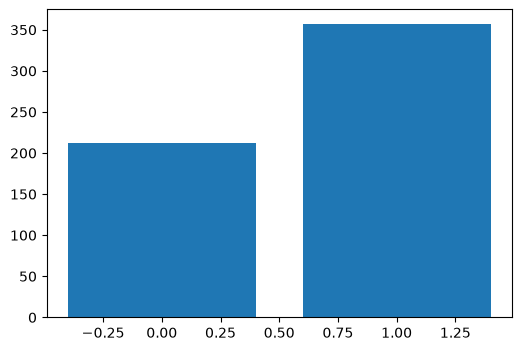

In [16]:
class_names=['Malignant','Benign']
fig,ax=plt.subplots(figsize=(6,4))
ax.bar(df.target.value_counts().index,df.target.value_counts().values)

In [17]:
features=df.drop('target',axis=1)
labels=df['target']
X_train,X_test,y_train,y_test=train_test_split(features,labels,test_size=.25,stratify=labels,random_state=24)

In [18]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(426, 30) (143, 30) (426,) (143,)


## Training

In [21]:
accuracy={}
for b in range(X_train.shape[1]):
    X_train['y_pred']=X_train['total']>=b
    accuracy[b]=accuracy_score(y_true=X_train['target'],
                              y_pred=X_train['y_pred'])

In [22]:
accuracy

{0: 0.6267605633802817,
 1: 0.6267605633802817,
 2: 0.6267605633802817,
 3: 0.6267605633802817,
 4: 0.6267605633802817,
 5: 0.6267605633802817,
 6: 0.6267605633802817,
 7: 0.6267605633802817,
 8: 0.6267605633802817,
 9: 0.6267605633802817,
 10: 0.6267605633802817,
 11: 0.6267605633802817,
 12: 0.6267605633802817,
 13: 0.6291079812206573,
 14: 0.6338028169014085,
 15: 0.6338028169014085,
 16: 0.6408450704225352,
 17: 0.647887323943662,
 18: 0.6572769953051644,
 19: 0.6619718309859155,
 20: 0.6713615023474179,
 21: 0.6901408450704225,
 22: 0.7089201877934272,
 23: 0.7323943661971831,
 24: 0.7699530516431925,
 25: 0.8051643192488263,
 26: 0.8286384976525821,
 27: 0.8474178403755869,
 28: 0.8450704225352113,
 29: 0.8192488262910798,
 30: 0.7394366197183099,
 31: 0.3732394366197183}

In [25]:
best_b=max(accuracy,key=accuracy.get)
best_b

27

In [26]:
for b in range(X_train.shape[1]):
    print(b)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
